# Day 2 - Supervised learning tutorial

***
Welcome to the tutorial on supervised learning. This guide will walk you through some fundamental concepts and essential steps for linear regression, logistic regression, decision trees, model evaluation and regularization.
***

**_NOTE_**: This notebook has been tested in the following environment:

* Python version = 3.14.2

## Overview

***

### Table of Contents
- [Overview](#Overview)
- [Before you begin](#Before-you-begin)
- [Linear regression](#Linear-regression)
- [Logistic regression](#Logistic-regression)
- [Decision trees](#Decision-trees)
- [Regularization](#Regularization)

### Objective

In this tutorial, you will learn how to create and evaluate different supervised machine learning models and their predictions for continuous and categorical data.

### Datasets

Datasets for the linear regression, logistic regression and regularization examples are randomly generated.

We will use the Iris dataset for the classification task with decision trees. Each row of the table represents an iris flower, including its species and dimensions of its botanical parts, sepal and petal, in centimeters.

### Useful resources

- [LinearRegression from sklearn](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [Video - Linear Regression with Gradient Descent](https://www.youtube.com/watch?v=L-Lsfu4ab74)
- [LogisticRegression from sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier)

## Before you begin
[Return to Table of Contents](#Table-of-Contents)  
***

### Setup

The guide is structured in the following way:  

- Create/read the data
- Split data for modelling
- Plot data
- Model and prediction
- Evaluation

### Import libraries

In [46]:
import numpy as np
import pandas as pd

# Data
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression

# Models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Linear regression
[Return to Table of Contents](#Table-of-Contents)  
***

Linear Regression is one of the most common and fundamental techniques for solving problems involving continuous target variables. Linear Regression is a simple yet powerful method that models the relationship between one or more independent variables and a continuous dependent variable by fitting a straight line to the data.

Linear Regression can be applied to various real-world problems, such as predicting house prices based on features like size and location, forecasting sales revenue for a business, estimating the impact of advertising spend on product sales, predicting a student's performance based on study hours, and many more scenarios where the target variable is continuous.

In [47]:
# Generate random data for modelling
np.random.seed(123)
number_of_instances = 100
predictor = np.arange(number_of_instances)
epsilon = np.random.uniform(-10,10, size=(number_of_instances,))
target = .4 * predictor + 3 + epsilon

In [48]:
# In order to use these arrays for regression modelling they need to be reshaped to 2D arrays
X = predictor.reshape(number_of_instances, 1)
y = target.reshape(number_of_instances, 1)

### Splitting data into training and test sets
To understand model performance, dividing the dataset into a training set and a test set is a good strategy.

Let's split the dataset using the `train_test_split()` function. You need to pass 3 parameters: features, target, and `test_size`. Additionally, you can set `random_state` to make the random split reproducible.

In [49]:
# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(80, 1) (80, 1) (20, 1) (20, 1)


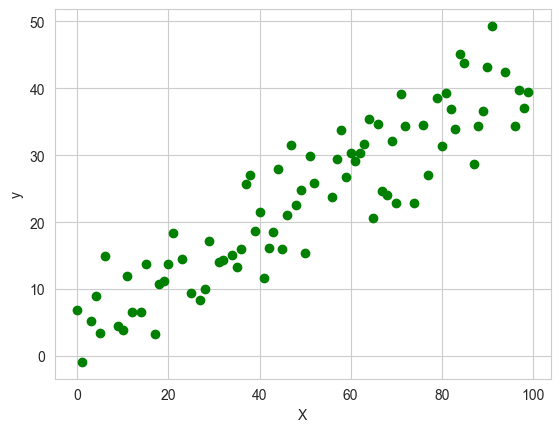

In [50]:
# plot data 
plt.scatter(X_train, y_train,  color='green')
plt.xlabel("X")
plt.ylabel("y")
plt.show()

### Model and prediction
Create a Linear Regression object using the `LinearRegression()` function.

The linear regression model takes the form: y = β0 + β1*x + ε, where β0 and β1 are the regression coefficients we want to find and ε is the random error term. The coefficients are estimated by minimising the sum of squared differences between the actual and predicted values (ordinary least squares).

In [51]:
# Create object that stands for Linear regression
model = LinearRegression(fit_intercept=True)
# Fit linear regression model
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [52]:
print(model.intercept_) # b0
print(model.coef_) # b1

[4.03219882]
[[0.38582515]]


In [53]:
# Generate predictions
y_pred = model.predict(X_test)

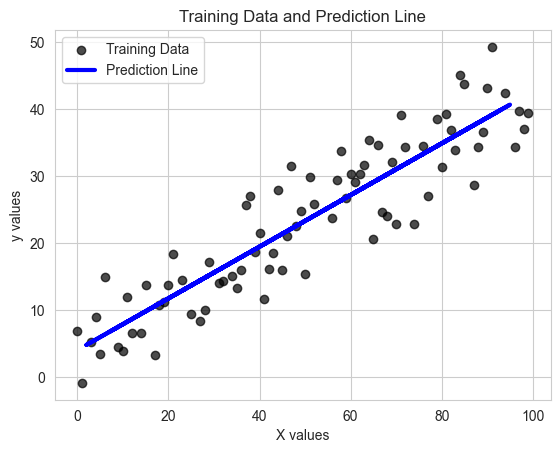

In [54]:
# Scatter plot for training data
plt.scatter(X_train, y_train, color='black', label='Training Data', alpha=0.7)

# Line plot for predictions
plt.plot(X_test, y_pred, color='blue', linewidth=3, label='Prediction Line')

# Add labels and title
plt.xlabel('X values')
plt.ylabel('y values')
plt.title('Training Data and Prediction Line')

# Add a legend
plt.legend()

# Add ticks for better readability
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Show the plot
plt.show()

The blue line shows how well the model fits the data.
The line closely follows the trend of the black points, indicating that the model has learned the relationship between `X` and `y` well.

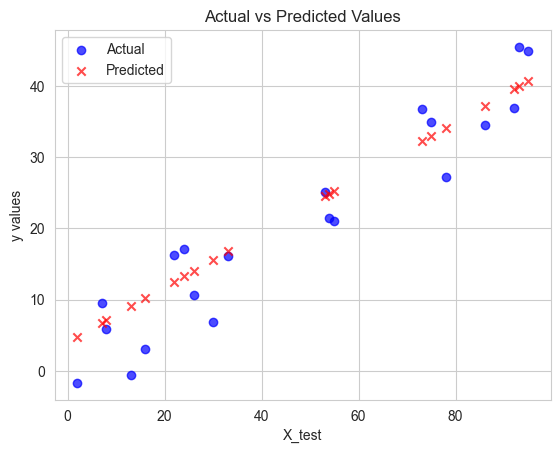

In [55]:
# Scatter plot for actual values
plt.scatter(X_test, y_test, color='blue', label='Actual', marker='o', alpha=0.7)

# Scatter plot for predicted values
plt.scatter(X_test, y_pred, color='red', label='Predicted', marker='x', alpha=0.7)

# Add labels and title
plt.xlabel('X_test')
plt.ylabel('y values')
plt.title('Actual vs Predicted Values')

# Add a legend
plt.legend()

# Show the plot
plt.show()

This plot shows predictions against the real values. Red points closer to blue points indicate more accurate predictions.

In [56]:
# You can check the differences between results
np.concatenate((y_pred, y_test), axis = 1)

array([[14.06365276, 10.63577311],
       [37.21316185, 34.54795133],
       [ 4.80384913, -1.66297093],
       [25.25258216, 21.08241578],
       [32.96908519, 34.88863759],
       [39.91393791, 45.45095628],
       [10.20540125,  3.04983461],
       [32.19743488, 36.66832716],
       [24.866757  , 21.45527668],
       [40.68558822, 44.83403597],
       [24.48093185, 25.10136013],
       [39.52811276, 36.91829731],
       [34.12656064, 27.2614103 ],
       [ 9.04792579, -0.60644207],
       [ 6.73297488,  9.49659477],
       [15.60695337,  6.8420988 ],
       [12.52035216, 16.2891065 ],
       [13.29200246, 17.04886765],
       [16.76442882, 16.07370195],
       [ 7.11880004,  5.81863803]])

### Model evaluation

Regression metrics are quantitative measures used to evaluate the performance of a regression model. Scikit-learn provides several metrics, each with its own strengths and limitations, to assess how well a model fits the data.

In [57]:
# Calculate MAE, MSE, R^2 and RMSE
print("MAE score:", mean_absolute_error(y_test, y_pred))
print("MSE score:", mean_squared_error(y_test, y_pred))
print("RMSE score:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R^2 score:", r2_score(y_test, y_pred))

MAE score: 4.208388957968042
MSE score: 23.746217706269338
RMSE score: 4.873009101804484
R^2 score: 0.8849783142306378


- **MAE:** on average, the model's predictions are off by about 4.21 units from the actual values.
- **MSE:** the average squared error is 23.75, meaning larger errors are penalized more heavily.
- **RMSE:** the typical error in the predictions is about 4.87 units, on the same scale as the target.
- **$R^2$:** the model explains 88% of the variation in the data, which is a strong fit.

### Batch gradient descent algorithm

Gradient descent is an optimization algorithm used to minimize a function (often a loss function in machine learning) by iteratively adjusting parameters in the direction of the steepest descent, as determined by the negative gradient.

In [58]:
# Find b0 and b1 for y = b0 + b1 * x to fit our data.
# Use gradient descent to estimate the coefficients, starting with b0 = 0 and b1 = 0.
b0 = 0
b1 = 0 

# L is the learning rate
# it affects how much b0 and b1 will change after each iteration
L = 0.0001
# number of iterations
iteration = 100000
n = float(len(X_train))

for i in range(iteration):
    y_pred2 = b0 + b1 * X_train
    # derivatives
    D_b0 = -(2/n) * sum(y_train - y_pred2)
    D_b1 = -(2/n) * sum(X_train * (y_train - y_pred2))
    b0 = b0 - L * D_b0
    b1 = b1 - L * D_b1
    # make a progress update every once in a while
    if i == 0 or (i+1) % (iteration/5) == 0: 
        print(f'Iteration: {i+1}')
        print(f'y = {b0[0]:.3f} + {b1[0]:.3f} * x  : {D_b0[0]:.3f}, {D_b1[0]:.3f}')
print(f'\nFinal Result:')
print(f'Iteration: {i+1}')
print(f'y = {b0[0]:.3f} + {b1[0]:.3f} * x')

Iteration: 1
y = 0.005 + 0.296 * x  : -46.792, -2958.518
Iteration: 20000
y = 2.484 + 0.409 * x  : -0.740, 0.011
Iteration: 40000
y = 3.437 + 0.395 * x  : -0.285, 0.004
Iteration: 60000
y = 3.803 + 0.389 * x  : -0.109, 0.002
Iteration: 80000
y = 3.944 + 0.387 * x  : -0.042, 0.001
Iteration: 100000
y = 3.998 + 0.386 * x  : -0.016, 0.000

Final Result:
Iteration: 100000
y = 3.998 + 0.386 * x


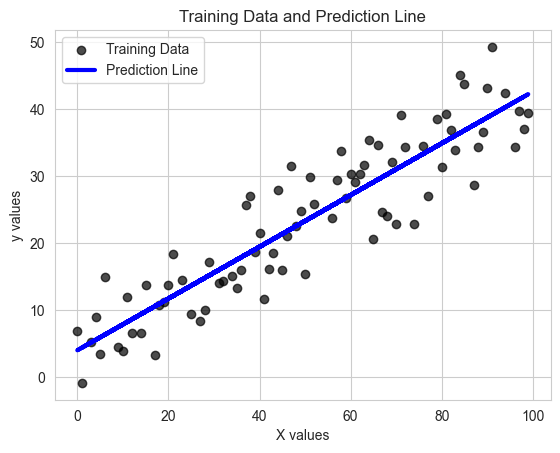

In [59]:
y_pred2 = b0 + b1 * X_train

# Scatter plot for training data
plt.scatter(X_train, y_train, color='black', label='Training Data', alpha=0.7)

# Line plot for predictions
plt.plot(X_train, y_pred2, color='blue', linewidth=3, label='Prediction Line')

# Add labels and title
plt.xlabel('X values')
plt.ylabel('y values')
plt.title('Training Data and Prediction Line')

# Add a legend
plt.legend()

# Add ticks for better readability
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Show the plot
plt.show()

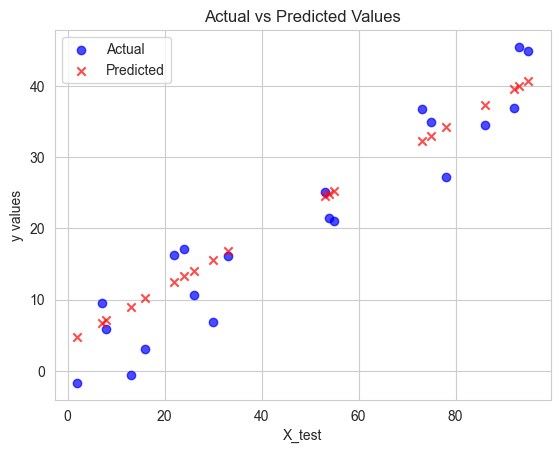

In [60]:
y_pred_test = b0 + b1 * X_test

# Scatter plot for actual values
plt.scatter(X_test, y_test, color='blue', label='Actual', marker='o', alpha=0.7)

# Scatter plot for predicted values
plt.scatter(X_test, y_pred_test, color='red', label='Predicted', marker='x', alpha=0.7)

# Add labels and title
plt.xlabel('X_test')
plt.ylabel('y values')
plt.title('Actual vs Predicted Values')

# Add a legend
plt.legend()

# Show the plot
plt.show()

In [61]:
# You can check the differences between results
np.concatenate((y_pred_test, y_pred, y_test), axis = 1)

array([[14.04313128, 14.06365276, 10.63577311],
       [37.22347022, 37.21316185, 34.54795133],
       [ 4.7709957 ,  4.80384913, -1.66297093],
       [25.24696177, 25.25258216, 21.08241578],
       [32.97374142, 32.96908519, 34.88863759],
       [39.9278431 , 39.91393791, 45.45095628],
       [10.17974145, 10.20540125,  3.04983461],
       [32.20106345, 32.19743488, 36.66832716],
       [24.86062279, 24.866757  , 21.45527668],
       [40.70052107, 40.68558822, 44.83403597],
       [24.4742838 , 24.48093185, 25.10136013],
       [39.54150412, 39.52811276, 36.91829731],
       [34.13275836, 34.12656064, 27.2614103 ],
       [ 9.02072451,  9.04792579, -0.60644207],
       [ 6.70269061,  6.73297488,  9.49659477],
       [15.58848721, 15.60695337,  6.8420988 ],
       [12.49777535, 12.52035216, 16.2891065 ],
       [13.27045331, 13.29200246, 17.04886765],
       [16.74750415, 16.76442882, 16.07370195],
       [ 7.08902959,  7.11880004,  5.81863803]])

### Model evaluation (gradient descent)
The metrics are very close to the ones from `LinearRegression`, since gradient descent converges towards the same least-squares solution.

In [62]:
# Calculate MAE, MSE, R^2 and RMSE
print("MAE score:", mean_absolute_error(y_test, y_pred_test))
print("MSE score:", mean_squared_error(y_test, y_pred_test))
print("RMSE score:", np.sqrt(mean_squared_error(y_test, y_pred_test)))
print("R^2 score:", r2_score(y_test, y_pred_test))

MAE score: 4.202923008907416
MSE score: 23.667486613786874
RMSE score: 4.8649241118219795
R^2 score: 0.8853596710888884


#### Advantages
Linear regression is straightforward to understand and computationally efficient. When its assumptions are reasonably met, it can model relationships between input features and a continuous target. Its coefficients are interpretable: each coefficient represents the expected change in the target for a one-unit increase in that feature, holding the other features constant. The model is also a useful baseline and typically requires little hyperparameter tuning.

#### Disadvantages
Linear regression models a linear relationship between the features and the target, so it may not capture nonlinear patterns unless the features are transformed. Its coefficient estimates can be sensitive to outliers. Strong multicollinearity can make coefficient estimates unstable and difficult to interpret. Irrelevant or noisy features may also reduce generalization, so feature selection and validation can be important.

## Logistic regression
[Return to Table of Contents](#Table-of-Contents)  
***

There are many classification methods available, but logistic regression is a common and useful method for solving binary classification problems. Despite its name, it is used for classification: it models the probability that an observation belongs to a class. Another category of classification is multinomial classification, which handles cases where the target variable has more than two classes.

Logistic regression can be used for various classification problems, such as spam detection, diabetes prediction, whether a given customer will purchase a particular product or churn to a competitor, whether a user will click on a given advertisement link, and many more.

In [63]:
# Generate random data for modelling
n_samples = 1000
np.random.seed(0)
X = np.random.normal(size = n_samples)
y = (X > 0).astype(np.float64)
X[X > 0] = X[X > 0] * 4
X = X + 0.3 * np.random.normal(size = n_samples)
X = X[:, np.newaxis]

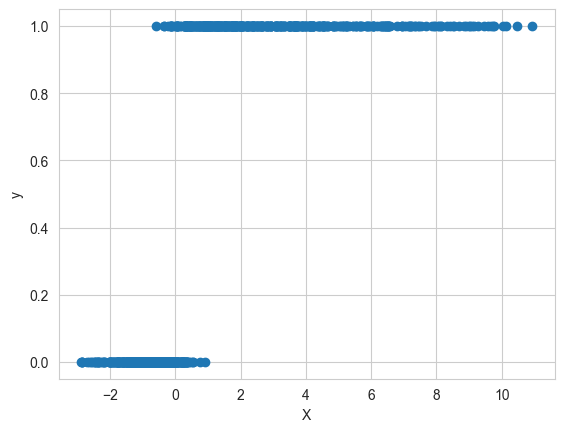

In [64]:
plt.scatter(X,y)
plt.xlabel("X")
plt.ylabel("y")
plt.show()

### Splitting data into training and test sets
To understand model performance, dividing the dataset into a training set and a test set is a good strategy.

Let's split the dataset using the `train_test_split()` function. You need to pass 3 parameters: features, target, and `test_size`. Additionally, you can set `random_state` to make the random split reproducible.

In [65]:
# Split X and y into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state = 0)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((750, 1), (250, 1), (750,), (250,))

### Model and prediction
Create a Logistic Regression classifier object using the `LogisticRegression()` function.

Then, fit your model on the training set using `fit()` and make predictions on the test set using `predict()`.

In [66]:
# Run the Logistic Regression classifier
logreg = LogisticRegression()
logreg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [67]:
y_pred_log = logreg.predict(X_test)
y_pred_log[:10]

array([1., 0., 0., 0., 0., 1., 0., 0., 0., 1.])

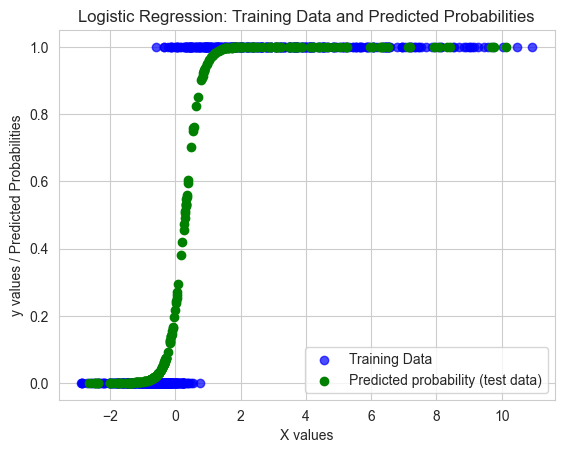

In [68]:
# Scatter plot for training data
plt.scatter(X_train, y_train, color='blue', label='Training Data', alpha=0.7)

# Scatter plot for predicted probabilities
plt.scatter(X_test, logreg.predict_proba(X_test)[:,1], color='green', label='Predicted probability (test data)')

# Add labels and title
plt.xlabel('X values')
plt.ylabel('y values / Predicted Probabilities')
plt.title('Logistic Regression: Training Data and Predicted Probabilities')

# Add a legend
plt.legend()

# Show the plot
plt.show()

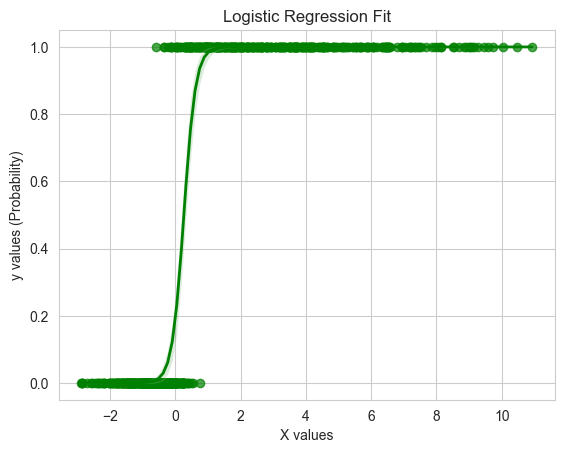

In [69]:
# Logistic regression plot
sns.regplot(x=X_train, y=y_train, logistic=True, color='green', scatter_kws={'alpha': 0.7}, line_kws={'linewidth': 2})

# Add labels and title
plt.xlabel('X values')
plt.ylabel('y values (Probability)')
plt.title('Logistic Regression Fit')

plt.show()

The scatter points show the observed class labels, while the logistic regression curve shows the model's predicted probability of class 1.

A smooth transition from 0 to 1 is expected for logistic regression, but it does not by itself show that the model fits well. Evaluate the model using held-out data and appropriate classification metrics, such as a confusion matrix, precision, recall, or ROC AUC, depending on the task.

In [70]:
# Examine predictions for the first three test samples
sample_X = X_test[:3]
sample_probabilities = logreg.predict_proba(sample_X)
sample_predictions = logreg.predict(sample_X)

for x_value, probabilities, prediction, true_class in zip(
    sample_X, sample_probabilities, sample_predictions, y_test[:3]
):
    print(
        f"X = {x_value[0]:.3f}, probabilities = {probabilities}, "
        f"predicted class = {prediction}, true class = {true_class}"
    )

X = 0.866, probabilities = [0.07721592 0.92278408], predicted class = 1.0, true class = 1.0
X = 0.069, probabilities = [0.72937503 0.27062497], predicted class = 0.0, true class = 1.0
X = -0.352, probabilities = [0.94403214 0.05596786], predicted class = 0.0, true class = 0.0


### Model evaluation
A confusion matrix is a table that is used to evaluate the performance of a classification model. It can also be used to visualize the performance of an algorithm. The idea behind a confusion matrix is that the numbers of correct and incorrect predictions are summed up for each class.

In [71]:
# Calculate the confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred_log)
cnf_matrix

array([[122,   8],
       [  8, 112]])

#### Visualizing the confusion matrix using a heatmap
Let's visualize the results of the model in the form of a confusion matrix heatmap using matplotlib and seaborn.

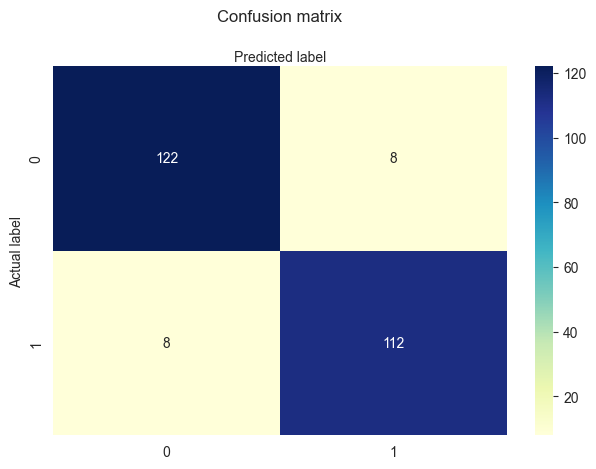

In [72]:
class_names = [0, 1] # names of classes
fig, ax = plt.subplots()
# Create heatmap (seaborn places the tick labels in the centre of each cell)
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu", fmt='g',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.xaxis.set_label_position("top")
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

Here, you can see the confusion matrix as a heatmap. The dimension of this matrix is 2×2 because this is a binary classification problem with two classes, 0 and 1. Diagonal values represent accurate predictions, while non-diagonal elements are inaccurate predictions.

#### Advantages
Logistic regression is relatively simple to implement and interpret, and it can be computationally efficient. It does not generally require feature scaling, although scaling can help optimization when features have very different ranges or when regularization is used. It also provides estimated class probabilities, which can be useful when decisions depend on more than a predicted class label.

#### Disadvantages
The standard logistic regression model is linear in its input features, so it may not capture nonlinear decision boundaries unless nonlinear features or transformations are added. It can overfit, particularly with many features or limited data, though regularization can help. Categorical features must be encoded numerically, and high-cardinality categories can create many features. Strong correlation among input features can make coefficient estimates less stable and harder to interpret. Features with little predictive information generally contribute little to performance.

## Decision trees
[Return to Table of Contents](#Table-of-Contents)  
***

Decision Trees are one of the most intuitive and versatile techniques. A Decision Tree works by splitting the data into branches based on feature values, creating a tree-like structure that leads to a decision or prediction at each leaf node. It can handle both categorical and continuous target variables, making it suitable for a wide range of tasks.

Decision Trees can be applied to various real-world problems, such as predicting customer churn based on behavior patterns, classifying whether an email is spam or not, determining loan approval based on applicant details, diagnosing diseases based on symptoms, and many more scenarios where interpretability and flexibility are important.

In [73]:
# Loading the dataset
data = load_iris()
X = data.data  
y = data.target 

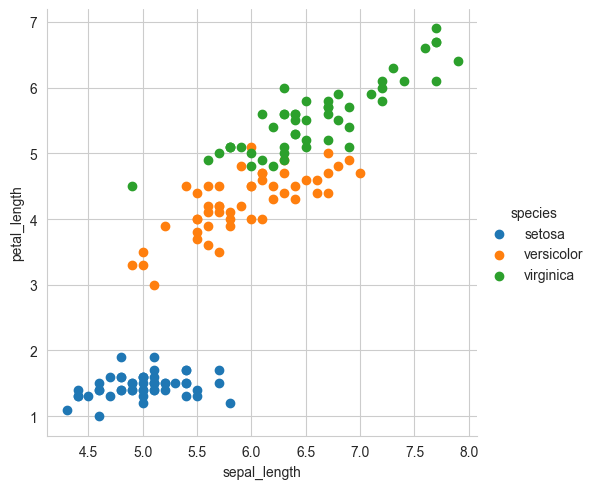

In [74]:
iris = sns.load_dataset('iris')
sns.set_style("whitegrid")
sns.FacetGrid(iris, hue ="species", 
              height = 5).map(plt.scatter, 
                              'sepal_length', 
                              'petal_length').add_legend()

### Splitting data into training and test sets
To understand model performance, dividing the dataset into a training set and a test set is a good strategy.

Let's split the dataset using the `train_test_split()` function. You need to pass 3 parameters: features, target, and `test_size`. Additionally, you can set `random_state` to make the random split reproducible.

In [75]:
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Shape of X: (150, 4)
Shape of y: (150,)


In [76]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state = 99)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((105, 4), (45, 4), (105,), (45,))

### Model and prediction
Create a Decision Tree classifier object using the `DecisionTreeClassifier()` function.

Then, fit your model on the training set using `fit()` and make predictions on the test set using `predict()`.

In [77]:
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [78]:
y_pred_clf = clf.predict(X_test)
y_pred_clf[:10]


array([2, 0, 1, 2, 0, 1, 1, 2, 0, 2])

In [79]:
from sklearn import tree
text_representation = tree.export_text(clf, feature_names=data.feature_names,
          class_names=data.target_names)
print(text_representation)

|--- petal length (cm) <= 2.45
|   |--- class: setosa
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: versicolor
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |--- class: virginica
|   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |--- petal length (cm) <= 5.45
|   |   |   |   |   |--- class: versicolor
|   |   |   |   |--- petal length (cm) >  5.45
|   |   |   |   |   |--- class: virginica
|   |--- petal width (cm) >  1.75
|   |   |--- class: virginica



The `plot_tree` graph for a decision tree provides a visual representation of the tree structure used by the model to make decisions.

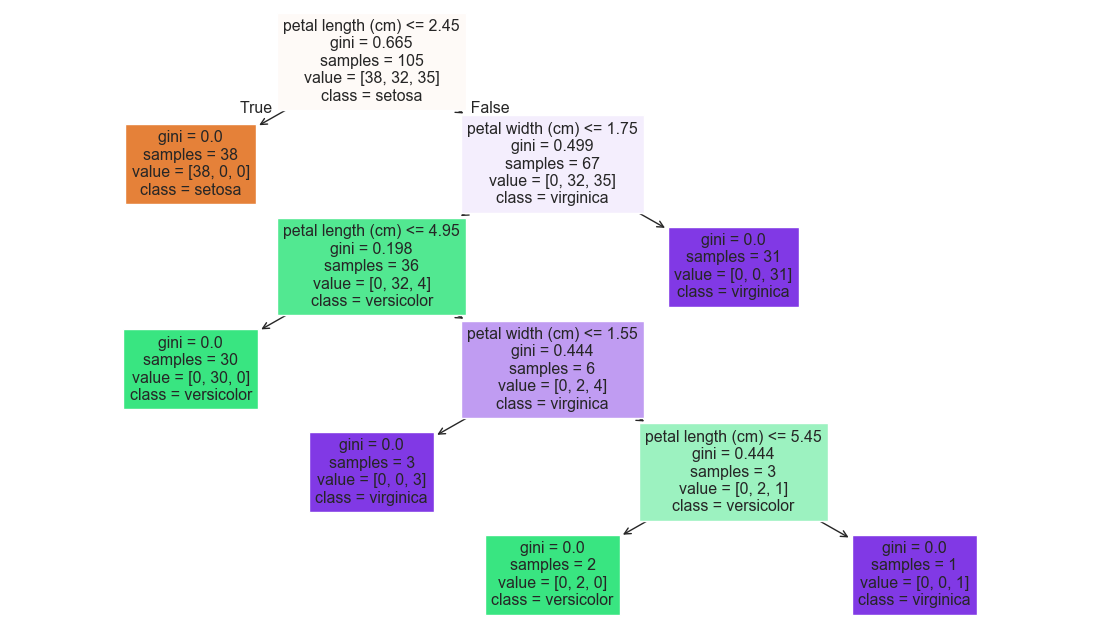

In [80]:
fig = plt.figure(figsize=(14,8))
_ = tree.plot_tree(clf, filled=True, feature_names=data.feature_names,
          class_names=data.target_names)

### Model evaluation

In [81]:
accuracy = accuracy_score(y_test, y_pred_clf)
print(f'Accuracy: {accuracy}')

Accuracy: 0.9555555555555556


In [82]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_clf)

# Print the confusion matrix
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[12  0  0]
 [ 0 17  1]
 [ 0  1 14]]


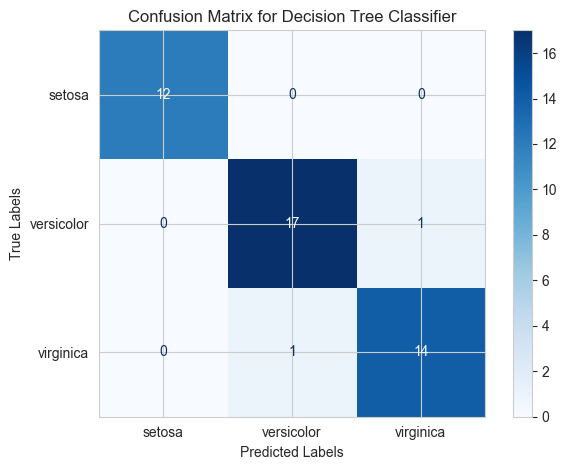

In [83]:
# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap="Blues")
disp.ax_.set_title("Confusion Matrix for Decision Tree Classifier")
disp.ax_.set_xlabel("Predicted Labels")
disp.ax_.set_ylabel("True Labels")
disp.figure_.tight_layout()

- **Setosa:** Perfect classification with no errors.
- **Versicolor:** One sample was misclassified as Virginica.
- **Virginica:** One sample was misclassified as Versicolor.

Overall, the model is performing well with high accuracy (95.6%), with only 2 misclassifications out of 45 total samples.

#### Advantages
Decision trees are easy to understand and interpret, as they mimic human decision-making processes. They can handle both numerical and categorical data and do not require feature scaling or normalization. Decision trees are versatile and can model complex relationships, including non-linear patterns.

#### Disadvantages
Decision trees are prone to overfitting, especially when they grow too deep or have many branches. They can be sensitive to small changes in the data, which may lead to entirely different tree structures. Decision trees may struggle with imbalanced datasets and can be biased toward features with more levels.

## Regularization
[Return to Table of Contents](#Table-of-Contents) 
***

Regularization is a technique used in machine learning to prevent overfitting, which otherwise causes models to perform poorly on unseen data. By adding a penalty for complexity, regularization encourages simpler and more generalizable models.

This tutorial covers three common regularized linear regression models. Each adds a different penalty to the loss function to help control model complexity and improve generalization.
- **Lasso regression:** uses an L1 penalty, which can shrink some coefficients to zero.
- **Ridge regression:** uses an L2 penalty, which shrinks coefficients toward zero.
- **Elastic Net regression:** combines L1 and L2 penalties.

In [84]:
# Generate a regression dataset with 100 samples, 5 features and some noise.
X, y = make_regression(n_samples=100, n_features=5, noise=0.1, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Lasso regression

Adds the sum of the absolute values of the coefficients (L1 penalty) to the loss function. This penalty can shrink some coefficients to exactly zero, which helps select the important features and ignore the less important ones.

In [85]:
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)

y_pred = lasso.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse}")
print("Coefficients:", lasso.coef_)

Mean Squared Error: 0.06362439921332522
Coefficients: [60.50305581 98.52475354 64.3929265  56.96061238 35.52928502]


The mean squared error (MSE) measures the average squared difference between the predicted and actual values; lower MSE indicates smaller prediction errors when models are evaluated on the same target and test data. The coefficients show the feature weights after regularization.

### Ridge regression

Adds the sum of the squared coefficients (L2 penalty) to the loss function. It handles multicollinearity by shrinking the coefficients of correlated features instead of eliminating them.

In [86]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred = ridge.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)
print("Coefficients:", ridge.coef_)

Mean Squared Error: 4.114050771972589
Coefficients: [59.87954432 97.15091098 63.24364738 56.31999433 35.34591136]


### Elastic Net regression

Adds both the L1 penalty (sum of absolute coefficients) and the L2 penalty (sum of squared coefficients) to the loss function. An extra hyperparameter, `l1_ratio`, controls the mix between L1 and L2 regularization.

Note: with `alpha=1.0` the penalty is strong for this data, so the coefficients are shrunk heavily and the MSE is much higher than for Lasso and Ridge. Try a smaller `alpha` (e.g. 0.01) to see the effect of the regularization strength.

In [87]:
elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5)
elastic_net.fit(X_train, y_train)

y_pred = elastic_net.predict(X_test)
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Coefficients:", elastic_net.coef_)

Mean Squared Error: 2662.329268376171
Coefficients: [41.2685658  60.6166494  34.45391474 37.4873701  26.29561474]
